# Nassau Candy — Exploratory Data Analysis

This notebook explores the **provided distributor CSV**. All tables and charts are computed from the local source file when the notebook is run; no example or simulated business values are used.

The analysis preserves every source row. It flags data-quality issues rather than silently correcting them. In particular, the order-to-ship intervals in this file are unusually long, so date-based analysis uses **Order Date** and does not draw fulfillment conclusions. Factory financial analysis is omitted because no product-to-factory mapping was supplied.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "Nassau Candy Distributor.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "data" / "Nassau Candy Distributor.csv").exists():
    raise FileNotFoundError(
        "Place this notebook in the project's notebooks folder and ensure "
        "data/Nassau Candy Distributor.csv exists."
    )
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_cleaning import load_data, quality_report
from src.metrics import aggregate_by, pareto_analysis, product_analysis, totals

DATA_PATH = PROJECT_ROOT / "data" / "Nassau Candy Distributor.csv"
df = load_data(DATA_PATH)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
quality = quality_report(df)
print(f"Loaded source: {DATA_PATH}")
print(f"Source shape: {quality['rows']:,} rows × {len(quality['column_names'])} columns")
print(f"Rows retained: {quality['rows_retained']:,}")
print(f"Order dates: {df['Order Date'].min():%Y-%m-%d} to {df['Order Date'].max():%Y-%m-%d}")
print(f"Ship dates:  {df['Ship Date'].min():%Y-%m-%d} to {df['Ship Date'].max():%Y-%m-%d}")
display(df.head())

Loaded source: C:\Users\Acer\Downloads\Nassau-Candy-Profitability-Analysis\data\Nassau Candy Distributor.csv
Source shape: 10,194 rows × 18 columns
Rows retained: 10,194
Order dates: 2024-01-02 to 2025-12-31
Ship dates:  2026-06-30 to 2030-06-28


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost,Date Gap Days,Date Anomaly,Gross Profit Reconciles
0,1,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28,909,True,True
1,2,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60,909,True,True
2,3,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00,909,True,True
3,4,US-2021-112326-CHO-SCR-58000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30,909,True,True
4,5,US-2021-141817-CHO-TRI-54000,2024-01-05,2026-07-05,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90,912,True,True


## 1. Dataset structure and data quality

The helper applies only documented parsing and whitespace trimming. Identifiers remain labels, dates are parsed day-month-year, and no observations are discarded. IQR outliers are review indicators, not removal rules.

In [2]:
dtype_table = pd.DataFrame({"Column": df.columns, "Parsed dtype": [str(df[c].dtype) for c in df.columns]})
missing_table = df[quality["column_names"]].isna().sum().rename("Missing values").to_frame()
validation_table = pd.DataFrame(
    [
        ("Source rows", quality["rows"]),
        ("Rows retained", quality["rows_retained"]),
        ("Source columns", quality["columns"]),
        ("Exact duplicate records", quality["exact_duplicates"]),
        ("Duplicate Row IDs", quality["duplicate_row_ids"]),
        ("Invalid Order Date", quality["invalid_dates"]["Order Date"]),
        ("Invalid Ship Date", quality["invalid_dates"]["Ship Date"]),
        ("Zero / negative sales", quality["zero_sales"] + quality["negative_sales"]),
        ("Zero / negative cost", quality["zero_cost"] + quality["negative_cost"]),
        ("Negative gross profit", quality["negative_gross_profit"]),
        ("Missing / nonpositive units", quality["missing_units"] + quality["invalid_or_nonpositive_units"]),
        ("Gross Profit ≠ Sales − Cost", quality["gross_profit_mismatches"]),
        ("Order-to-ship gaps > 365 days", quality["date_anomalies"]),
        ("Product ID/name conflicts", quality["product_id_name_conflicts"] + quality["product_name_id_conflicts"]),
        ("ID-prefix/division mismatch rows", quality["division_prefix_mismatch_rows"]),
    ],
    columns=["Validation check", "Count"],
)
print("Parsed data types")
display(dtype_table)
print("Missing values per source field")
display(missing_table)
print("Validation summary")
display(validation_table)
print("IQR outlier counts (1.5 × IQR; observations are retained):")
display(pd.Series(quality["outliers_iqr"], name="IQR outliers").to_frame())
print("Order-to-ship gap (days):", {key: quality[key] for key in ["date_gap_min", "date_gap_median", "date_gap_max"]})
print("Product ID/name conflicts:", quality["product_id_name_conflicts"], quality["product_name_id_conflicts"])
print("Division-prefix exceptions:")
display(pd.DataFrame(quality["division_prefix_mismatches"]))

Parsed data types


,Column,Parsed dtype
0,Row ID,string
1,Order ID,string
2,Order Date,datetime64[us]
3,Ship Date,datetime64[us]
4,Ship Mode,str
5,Customer ID,string
6,Country/Region,str
7,City,string
8,State/Province,string
9,Postal Code,string


Missing values per source field


,Missing values
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Country/Region,0
City,0
State/Province,0
Postal Code,0


Validation summary


,Validation check,Count
0,Source rows,10194
1,Rows retained,10194
2,Source columns,18
3,Exact duplicate records,0
4,Duplicate Row IDs,0
5,Invalid Order Date,0
6,Invalid Ship Date,0
7,Zero / negative sales,0
8,Zero / negative cost,0
9,Negative gross profit,0


IQR outlier counts (1.5 × IQR; observations are retained):


,IQR outliers
Sales,245
Units,175
Gross Profit,217
Cost,397


Order-to-ship gap (days): {'date_gap_min': 904, 'date_gap_median': 1274.0, 'date_gap_max': 1642}
Product ID/name conflicts: 0 0
Division-prefix exceptions:


,Product ID,Product Name,Division
0,OTH-FIZ-56000,Fizzy Lifting Drinks,Sugar


### Cleaning decisions

- No missing values, exact duplicate rows, duplicate Row IDs, invalid dates, nonpositive sales/cost/units, negative gross profit, or gross-profit reconciliation failures were observed in the supplied file.
- Monetary values and units are parsed numerically; source IDs and postal codes are kept as text. Date strings are parsed with `%d-%m-%Y`.
- Labels are trimmed but not otherwise renamed. An apparent product-ID prefix/division mismatch is reported without changing the source division label.
- All records are retained, including IQR outliers and the unusually long order-to-ship intervals. Validate source dates before operational interpretation.
- The source does not state a currency; values below use source units.

Row-level numeric descriptive statistics


,count,mean,std,min,25%,50%,75%,max
Sales,10194.0,13.908537,11.341020,1.25,7.2,10.80,18.00,260.0
Cost,10194.0,4.742087,5.061647,0.60,2.4,3.60,5.70,130.0
Gross Profit,10194.0,9.166451,6.643740,0.25,4.9,7.47,12.25,130.0
Units,10194.0,3.791838,2.228317,1.00,2.0,3.00,5.00,14.0


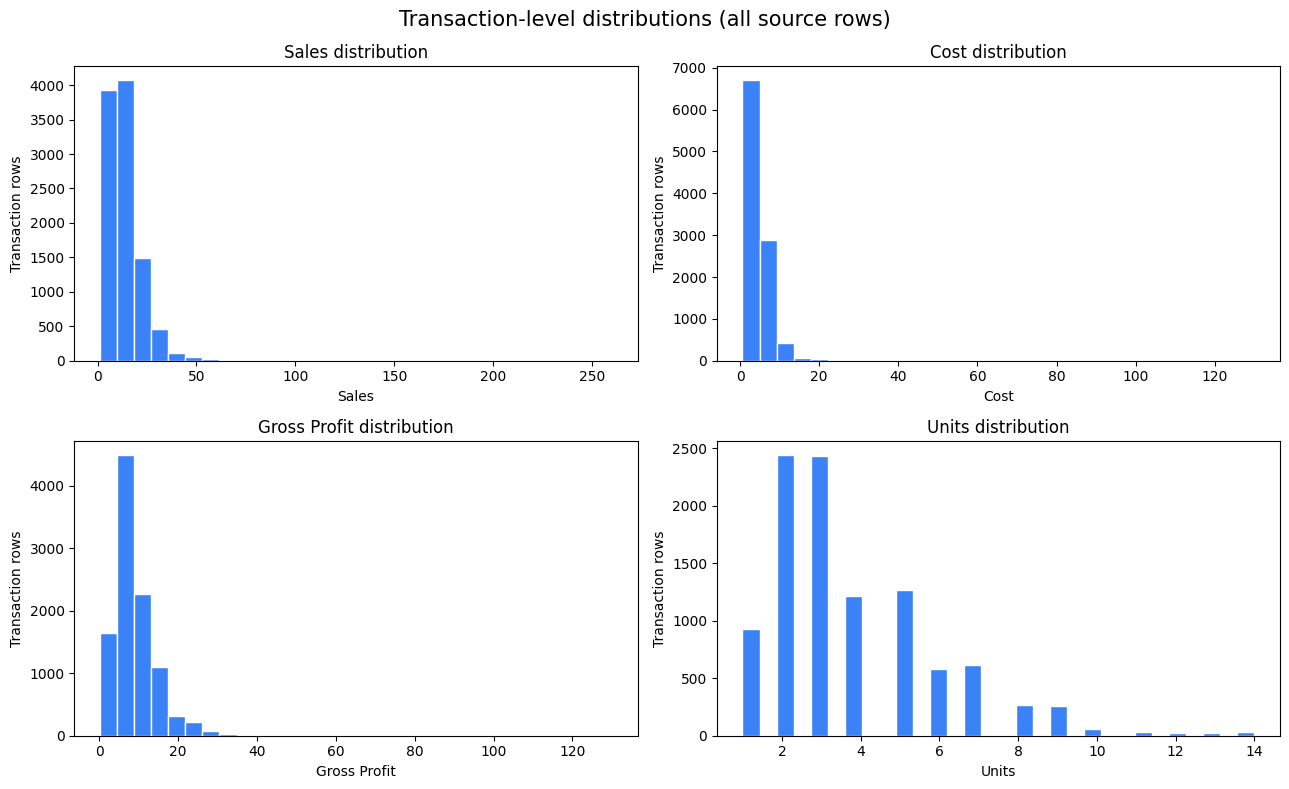

In [3]:
numeric_columns = ["Sales", "Cost", "Gross Profit", "Units"]
print("Row-level numeric descriptive statistics")
display(df[numeric_columns].describe().T)

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, column in zip(axes.flat, numeric_columns):
    ax.hist(df[column].dropna(), bins=30, color="#3b82f6", edgecolor="white")
    ax.set_title(f"{column} distribution")
    ax.set_xlabel(column)
    ax.set_ylabel("Transaction rows")
fig.suptitle("Transaction-level distributions (all source rows)", fontsize=15)
fig.tight_layout()
plt.show()

## 2. Financial overview and transaction relationships

Gross margin and profit per unit are computed from aggregate totals (weighted), not as averages of transaction-level ratios. The scatter plot below samples transaction rows only for visual legibility; calculations use the full dataset.

,Actual dataset value
Sales,141783.630000
Cost,48340.830000
Gross Profit,93442.800000
Units,38654.000000
Gross Margin %,65.905211
Profit per Unit,2.417416
Product Count,15.000000
Division Count,3.000000


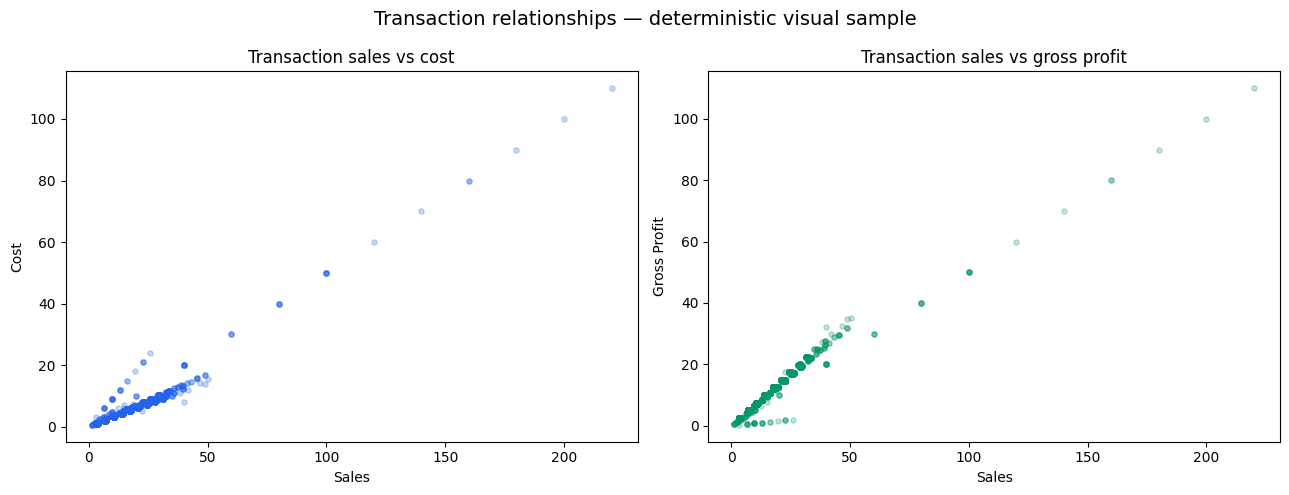

Gross profit reconciliation passed for all 10,194 source rows.


In [4]:
overall = totals(df)
display(pd.Series(overall, name="Actual dataset value").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sample = df.sample(n=min(3000, len(df)), random_state=7)
axes[0].scatter(sample["Sales"], sample["Cost"], alpha=0.25, s=14, color="#2563eb")
axes[0].set(title="Transaction sales vs cost", xlabel="Sales", ylabel="Cost")
axes[1].scatter(sample["Sales"], sample["Gross Profit"], alpha=0.25, s=14, color="#059669")
axes[1].set(title="Transaction sales vs gross profit", xlabel="Sales", ylabel="Gross Profit")
fig.suptitle("Transaction relationships — deterministic visual sample", fontsize=14)
fig.tight_layout()
plt.show()

assert df["Gross Profit Reconciles"].all(), "At least one row does not reconcile Gross Profit = Sales - Cost."
print(f"Gross profit reconciliation passed for all {len(df):,} source rows.")

## 3. Product line profitability

Products are compared using total sales, cost, units, gross profit, weighted gross margin, profit per unit, and contribution to filtered totals (the complete dataset in this notebook). Quadrants use median product sales and median product gross profit. Margin risk uses product-level margin quartiles; these are descriptive thresholds, not business targets.

,Product ID,Product Name,Division,Sales,Cost,Units,Gross Profit,Gross Margin %,Profit per Unit,Revenue Contribution %,Profit Contribution %,Profitability Segment,Margin Risk
0,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,Chocolate,"27,874.80","8,517.30",7743,"19,357.50",69.44%,2.50,19.66%,20.72%,High sales / High profit,High Margin / Low Risk
1,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,Chocolate,"28,485.00","9,874.80",7596,"18,610.20",65.33%,2.45,20.09%,19.92%,High sales / High profit,Medium Margin / Monitor
2,CHO-MIL-31000,Wonka Bar - Milk Chocolate,Chocolate,"26,867.75","9,424.38",8267,"17,443.37",64.92%,2.11,18.95%,18.67%,High sales / High profit,Medium Margin / Monitor
3,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,Chocolate,"23,574.95","6,755.00",6755,"16,819.95",71.35%,2.49,16.63%,18.00%,High sales / High profit,High Margin / Low Risk
4,CHO-FUD-51000,Wonka Bar - Fudge Mallows,Chocolate,"24,890.40","8,296.80",6914,"16,593.60",66.67%,2.40,17.56%,17.76%,High sales / High profit,Medium Margin / Monitor
5,OTH-LIC-15000,Lickable Wallpaper,Other,"7,860.00","3,930.00",393,"3,930.00",50.00%,10.00,5.54%,4.21%,High sales / High profit,Medium Margin / Monitor
6,OTH-GUM-21000,Wonka Gum,Other,597.50,286.80,478,310.70,52.00%,0.65,0.42%,0.33%,High sales / High profit,Medium Margin / Monitor
7,SUG-EVE-47000,Everlasting Gobstopper,Sugar,130.00,26.00,13,104.00,80.00%,8.00,0.09%,0.11%,Low sales / High profit,High Margin / Low Risk
8,OTH-KAZ-38000,Kazookles,Other,"1,205.75","1,113.00",371,92.75,7.69%,0.25,0.85%,0.10%,High sales / Low profit,Low Margin / High Risk
9,SUG-HAI-55000,Hair Toffee,Sugar,76.50,17.00,17,59.50,77.78%,3.50,0.05%,0.06%,Low sales / Low profit,High Margin / Low Risk


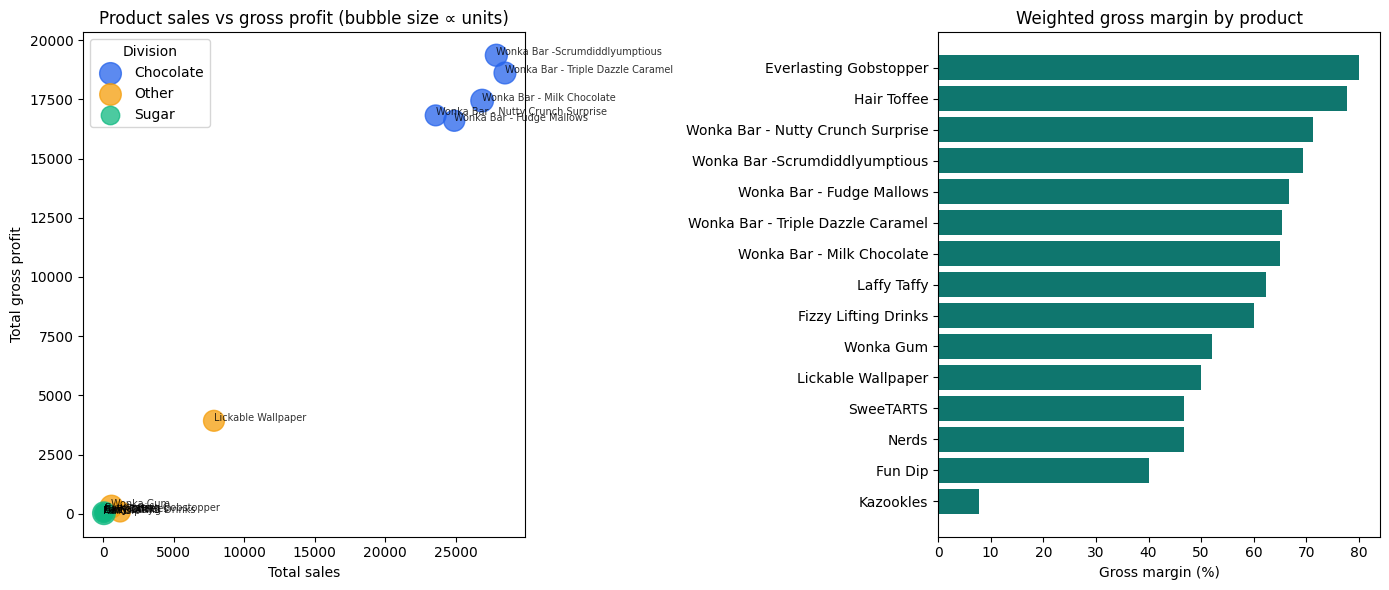

Median product sales: 597.5
Median product gross profit: 104.0
Margin risk thresholds (product aggregate margin): {0.25: 48.33333333333333, 0.75: 68.05555555555554}


,Product count
Median-based segment,
High sales / High profit,7
Low sales / Low profit,6
Low sales / High profit,1
High sales / Low profit,1


,Product count
Margin risk category,
Medium Margin / Monitor,7
High Margin / Low Risk,4
Low Margin / High Risk,4


In [5]:
products = product_analysis(df)
product_columns = [
    "Product ID", "Product Name", "Division", "Sales", "Cost", "Units", "Gross Profit",
    "Gross Margin %", "Profit per Unit", "Revenue Contribution %", "Profit Contribution %",
    "Profitability Segment", "Margin Risk",
]
display(products[product_columns].style.format({
    "Sales": "{:,.2f}", "Cost": "{:,.2f}", "Gross Profit": "{:,.2f}",
    "Gross Margin %": "{:.2f}%", "Profit per Unit": "{:,.2f}",
    "Revenue Contribution %": "{:.2f}%", "Profit Contribution %": "{:.2f}%",
}))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
division_colors = {name: color for name, color in zip(sorted(products["Division"].unique()), ["#2563eb", "#f59e0b", "#10b981"])}
for division, group in products.groupby("Division"):
    axes[0].scatter(group["Sales"], group["Gross Profit"], s=45 + group["Units"] / group["Units"].max() * 220,
                    alpha=0.75, label=division, color=division_colors[division])
    for _, row in group.iterrows():
        axes[0].annotate(row["Product Name"], (row["Sales"], row["Gross Profit"]), fontsize=7, alpha=0.8)
axes[0].set(title="Product sales vs gross profit (bubble size ∝ units)", xlabel="Total sales", ylabel="Total gross profit")
axes[0].legend(title="Division")

margin_order = products.sort_values("Gross Margin %", ascending=True)
axes[1].barh(margin_order["Product Name"], margin_order["Gross Margin %"], color="#0f766e")
axes[1].set(title="Weighted gross margin by product", xlabel="Gross margin (%)")
fig.tight_layout()
plt.show()

print("Median product sales:", products["Sales"].median())
print("Median product gross profit:", products["Gross Profit"].median())
print("Margin risk thresholds (product aggregate margin):", products["Gross Margin %"].quantile([0.25, 0.75]).to_dict())
display(products["Profitability Segment"].value_counts().rename_axis("Median-based segment").to_frame("Product count"))
display(products["Margin Risk"].value_counts().rename_axis("Margin risk category").to_frame("Product count"))

## 4. Division performance

Division gross margin is total gross profit divided by total sales for that division. The box plot shows transaction-level margin distribution to complement the weighted division results.

,Division,Sales,Cost,Gross Profit,Units,Gross Margin %,Profit per Unit,Revenue Contribution %,Profit Contribution %
0,Chocolate,131692.90,42868.28,88824.62,37275,67.448298,2.382954,92.883008,95.057747
1,Other,9663.25,5329.80,4333.45,1242,44.844643,3.489090,6.815491,4.637543
2,Sugar,427.48,142.75,284.73,137,66.606625,2.078321,0.301502,0.304710


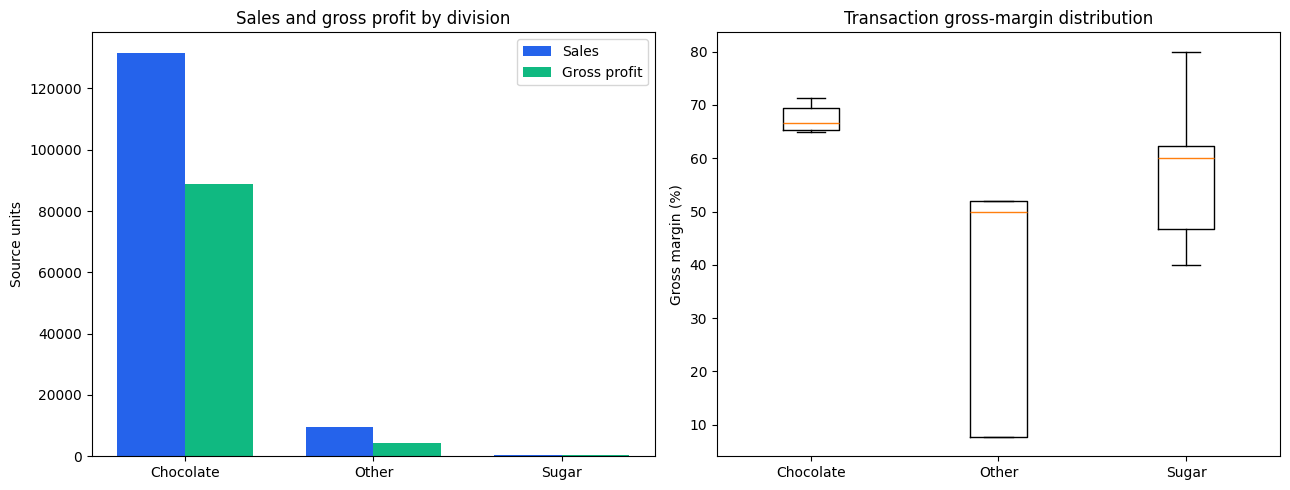

In [6]:
divisions = aggregate_by(df, "Division").sort_values("Gross Profit", ascending=False)
display(divisions)

row_margin = df["Gross Profit"].div(df["Sales"].where(df["Sales"].ne(0))).mul(100)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
x = np.arange(len(divisions))
axes[0].bar(x - 0.18, divisions["Sales"], width=0.36, label="Sales", color="#2563eb")
axes[0].bar(x + 0.18, divisions["Gross Profit"], width=0.36, label="Gross profit", color="#10b981")
axes[0].set_xticks(x, divisions["Division"])
axes[0].set(title="Sales and gross profit by division", ylabel="Source units")
axes[0].legend()
margin_groups = [row_margin[df["Division"].eq(name)].dropna() for name in divisions["Division"]]
axes[1].boxplot(margin_groups, tick_labels=divisions["Division"], showfliers=True)
axes[1].set(title="Transaction gross-margin distribution", ylabel="Gross margin (%)")
fig.tight_layout()
plt.show()

## 5. Cost and margin diagnostics

The product-level scatter helps distinguish absolute cost from margin rate. A high absolute cost is not, by itself, evidence of avoidable or excessive cost; this source contains no cost standards or production benchmarks.

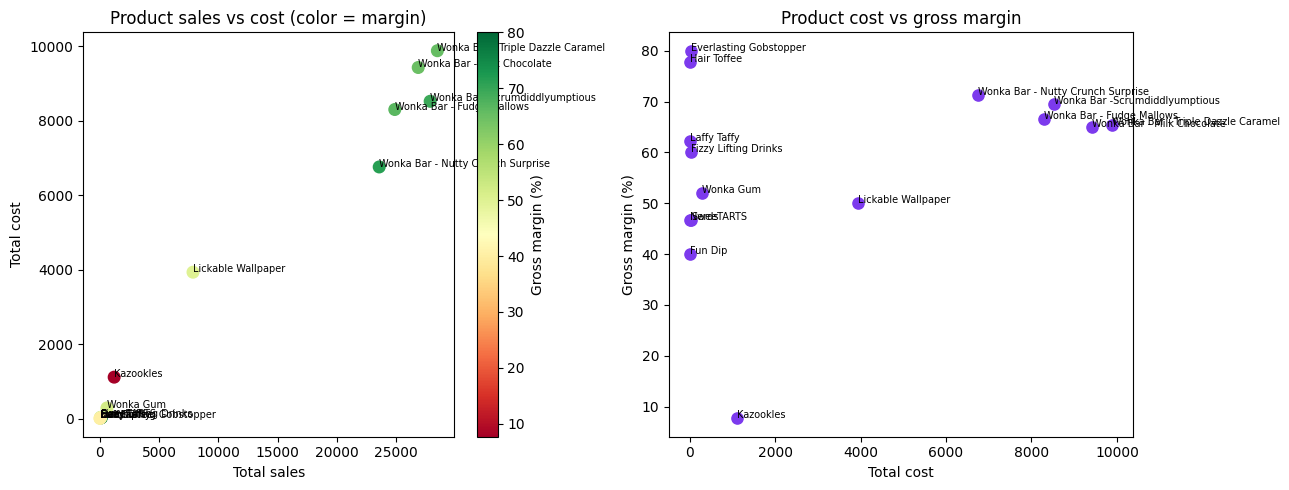

High sales / low margin definition: sales ≥ product median (597.50) and margin < Q1 (48.33%).


,Product ID,Product Name,Division,Sales,Cost,Units,Gross Profit,Gross Margin %,Profit per Unit,Revenue Contribution %,Profit Contribution %,Profitability Segment,Margin Risk
8,OTH-KAZ-38000,Kazookles,Other,1205.75,1113.0,371,92.75,7.692308,0.25,0.850416,0.099259,High sales / Low profit,Low Margin / High Risk


Cost-heavy definition: product total cost > Q3 (7,525.90).


,Product Name,Division,Sales,Cost,Gross Profit,Gross Margin %
1,Wonka Bar - Triple Dazzle Caramel,Chocolate,28485.00,9874.80,18610.20,65.333333
2,Wonka Bar - Milk Chocolate,Chocolate,26867.75,9424.38,17443.37,64.923077
0,Wonka Bar -Scrumdiddlyumptious,Chocolate,27874.80,8517.30,19357.50,69.444444
4,Wonka Bar - Fudge Mallows,Chocolate,24890.40,8296.80,16593.60,66.666667


In [7]:
margin_q1 = products["Gross Margin %"].quantile(0.25)
sales_median = products["Sales"].median()
cost_q3 = products["Cost"].quantile(0.75)
high_sales_low_margin = products[products["Sales"].ge(sales_median) & products["Gross Margin %"].lt(margin_q1)]
cost_heavy = products[products["Cost"].gt(cost_q3)].sort_values("Cost", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
scatter = axes[0].scatter(products["Sales"], products["Cost"], c=products["Gross Margin %"], cmap="RdYlGn", s=70)
for _, row in products.iterrows():
    axes[0].annotate(row["Product Name"], (row["Sales"], row["Cost"]), fontsize=7)
axes[0].set(title="Product sales vs cost (color = margin)", xlabel="Total sales", ylabel="Total cost")
fig.colorbar(scatter, ax=axes[0], label="Gross margin (%)")
axes[1].scatter(products["Cost"], products["Gross Margin %"], color="#7c3aed", s=65)
for _, row in products.iterrows():
    axes[1].annotate(row["Product Name"], (row["Cost"], row["Gross Margin %"]), fontsize=7)
axes[1].set(title="Product cost vs gross margin", xlabel="Total cost", ylabel="Gross margin (%)")
fig.tight_layout()
plt.show()

print(f"High sales / low margin definition: sales ≥ product median ({sales_median:,.2f}) and margin < Q1 ({margin_q1:.2f}%).")
display(high_sales_low_margin[product_columns])
print(f"Cost-heavy definition: product total cost > Q3 ({cost_q3:,.2f}).")
display(cost_heavy[["Product Name", "Division", "Sales", "Cost", "Gross Profit", "Gross Margin %"]])

## 6. Revenue and gross-profit concentration

Products are sorted descending by the selected metric. The count reported is the minimum number of products needed for cumulative contribution to reach or exceed 80%.

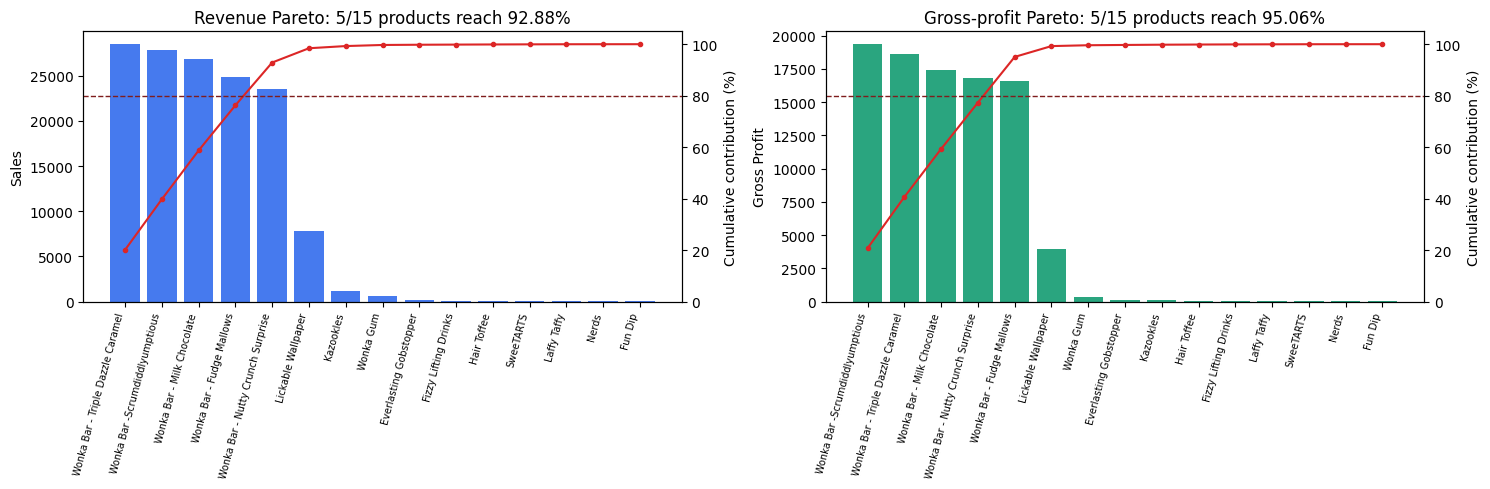

Sales: 5 of 15 products (33.3%) reach 92.88% cumulative contribution.
Gross Profit: 5 of 15 products (33.3%) reach 95.06% cumulative contribution.


In [8]:
pareto_results = {}
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, metric, title in zip(axes, ["Sales", "Gross Profit"], ["Revenue Pareto", "Gross-profit Pareto"]):
    ordered, count, covered = pareto_analysis(products, metric)
    pareto_results[metric] = (ordered, count, covered)
    positions = np.arange(len(ordered))
    ax.bar(positions, ordered[metric], color="#2563eb" if metric == "Sales" else "#059669", alpha=0.85)
    ax.set_xticks(positions, ordered["Product Name"], rotation=75, ha="right", fontsize=7)
    ax.set_ylabel(metric)
    ax.set_title(f"{title}: {count}/{len(ordered)} products reach {covered:.2f}%")
    line_ax = ax.twinx()
    line_ax.plot(positions, ordered["Cumulative Contribution %"], color="#dc2626", marker="o", markersize=3)
    line_ax.axhline(80, color="#7f1d1d", linestyle="--", linewidth=1)
    line_ax.set_ylim(0, 105)
    line_ax.set_ylabel("Cumulative contribution (%)")
fig.tight_layout()
plt.show()

for metric, (_, count, covered) in pareto_results.items():
    print(f"{metric}: {count} of {len(products)} products ({count / len(products) * 100:.1f}%) reach {covered:.2f}% cumulative contribution.")

## 7. Regional, state, and city results

These are descriptive aggregations. No state/city coordinates or operational causal variables are supplied, so no geographic map or logistics conclusion is inferred.

,Region,Sales,Cost,Gross Profit,Units,Gross Margin %,Profit per Unit,Revenue Contribution %,Profit Contribution %
3,Pacific,46301.53,15815.59,30485.94,12466,65.842187,2.445527,32.656471,32.625242
0,Atlantic,41197.24,14223.54,26973.70,11159,65.474532,2.417215,29.056415,28.866537
2,Interior,32037.60,10755.11,21282.49,8820,66.429726,2.412981,22.596121,22.775955
1,Gulf,22247.26,7546.59,14700.67,6209,66.078564,2.367639,15.690993,15.732266


Top 10 states by gross profit


,State/Province,Sales,Cost,Gross Profit,Units,Gross Margin %,Profit per Unit,Revenue Contribution %,Profit Contribution %
5,California,27917.40,9437.98,18479.42,7667,66.193199,2.410254,19.690143,19.776184
34,New York,15541.03,5318.59,10222.44,4224,65.777107,2.420085,10.961089,10.939783
51,Texas,13416.09,4506.56,8909.53,3724,66.409289,2.392462,9.462369,9.534742
43,Pennsylvania,8027.03,2801.56,5225.47,2153,65.098424,2.427065,5.661465,5.592159
55,Washington,6921.15,2354.51,4566.64,1883,65.980942,2.425194,4.881487,4.887097
13,Illinois,6898.96,2341.28,4557.68,1845,66.063291,2.470287,4.865837,4.877508
39,Ohio,6768.95,2355.92,4413.03,1759,65.195193,2.508829,4.774141,4.722707
10,Florida,4804.02,1596.91,3207.11,1379,66.758881,2.325678,3.388276,3.432164
36,North Carolina,3450.86,1119.70,2331.16,983,67.553016,2.371475,2.433892,2.494745
2,Arizona,3587.55,1297.44,2290.11,862,63.834929,2.656740,2.530299,2.450815


Top 10 cities by gross profit


,City,Sales,Cost,Gross Profit,Units,Gross Margin %,Profit per Unit,Revenue Contribution %,Profit Contribution %
335,New York City,12514.90,4274.39,8240.51,3417,65.845592,2.411621,8.826759,8.818775
270,Los Angeles,10408.75,3510.14,6898.61,2879,66.277027,2.396183,7.341292,7.382709
380,Philadelphia,7415.52,2601.70,4813.82,1981,64.915475,2.429995,5.230167,5.151622
446,San Francisco,7018.61,2367.84,4650.77,1935,66.263405,2.403499,4.950226,4.977130
460,Seattle,5893.39,2012.71,3880.68,1590,65.848009,2.440679,4.156608,4.153001
211,Houston,5429.41,1881.98,3547.43,1466,65.337302,2.419802,3.829363,3.796365
82,Chicago,4263.92,1463.34,2800.58,1132,65.680876,2.474011,3.007343,2.997106
96,Columbus,3357.39,1198.36,2159.03,836,64.306798,2.582572,2.367967,2.310536
445,San Diego,2348.88,781.36,1567.52,670,66.734784,2.339582,1.656665,1.677518
472,Springfield,2375.00,834.88,1540.12,649,64.847158,2.373066,1.675088,1.648195


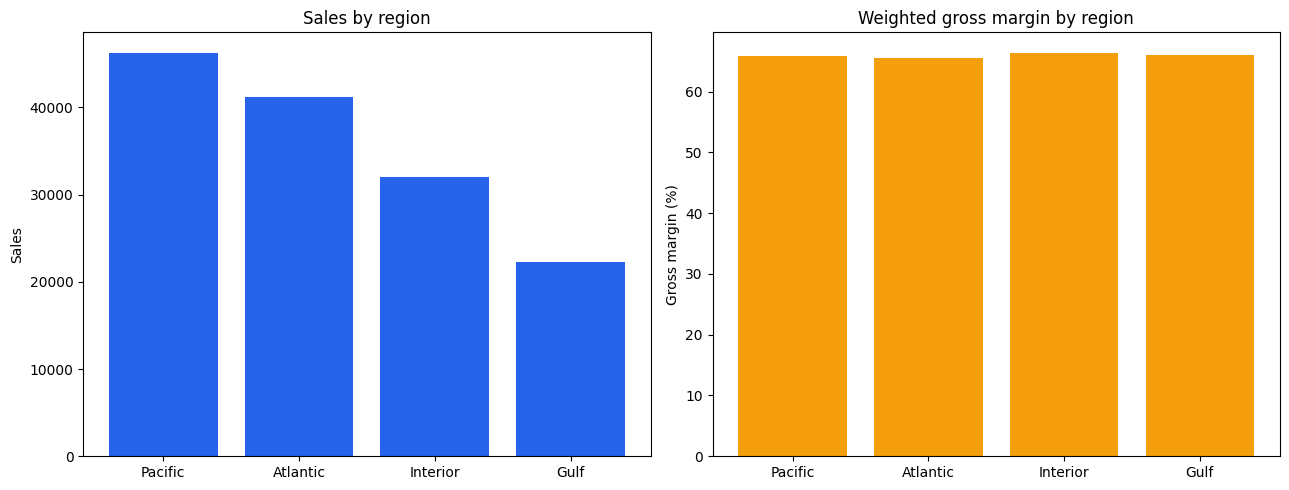

In [9]:
regions = aggregate_by(df, "Region").sort_values("Gross Profit", ascending=False)
states = aggregate_by(df, "State/Province").sort_values("Gross Profit", ascending=False)
cities = aggregate_by(df, "City").sort_values("Gross Profit", ascending=False)
display(regions)
print("Top 10 states by gross profit")
display(states.head(10))
print("Top 10 cities by gross profit")
display(cities.head(10))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(regions["Region"], regions["Sales"], color="#2563eb", label="Sales")
axes[0].set(title="Sales by region", ylabel="Sales")
axes[1].bar(regions["Region"], regions["Gross Margin %"], color="#f59e0b")
axes[1].set(title="Weighted gross margin by region", ylabel="Gross margin (%)")
fig.tight_layout()
plt.show()

## 8. Order-date trends

Monthly and quarterly summaries use Order Date. The unusual ship-date offsets make Ship Date unsuitable for calendar interpretation until confirmed by the data owner. Changes across the two available years are descriptive, not proof of a long-term trend or seasonality.

Annual summary


,Period,Sales,Cost,Gross Profit,Units,Gross Margin %,Profit per Unit,Revenue Contribution %,Profit Contribution %
0,2024,57956.20,19804.77,38151.43,15899,65.828039,2.399612,40.87651,40.828646
1,2025,83827.43,28536.06,55291.37,22755,65.958565,2.429856,59.12349,59.171354


Monthly summary


,Period,Sales,Cost,Gross Profit,Units,Gross Margin %
0,2024-01,2093.90,727.76,1366.14,566,65.243803
1,2024-02,1379.87,471.28,908.59,398,65.846058
2,2024-03,4138.90,1467.74,2671.16,1125,64.537921
3,2024-04,3988.22,1375.41,2612.81,1079,65.513186
4,2024-05,3951.52,1336.08,2615.44,1099,66.188201
5,2024-06,3518.76,1188.04,2330.72,1010,66.236970
6,2024-07,3865.38,1300.12,2565.26,1107,66.365015
7,2024-08,4477.65,1531.78,2945.87,1227,65.790537
8,2024-09,7912.10,2705.40,5206.70,2105,65.806802
9,2024-10,4815.98,1696.52,3119.46,1237,64.773110


Quarterly summary


,Period,Sales,Cost,Gross Profit,Units,Gross Margin %
0,2024Q1,7612.67,2666.78,4945.89,2089,64.969190
1,2024Q2,11458.50,3899.53,7558.97,3188,65.968233
2,2024Q3,16255.13,5537.30,10717.83,4439,65.935062
3,2024Q4,22629.90,7701.16,14928.74,6183,65.969094
4,2025Q1,11465.99,3871.25,7594.74,3178,66.237106
5,2025Q2,17693.05,5973.96,11719.09,4854,66.235556
6,2025Q3,23255.37,7978.09,15277.28,6243,65.693558
7,2025Q4,31413.02,10712.76,20700.26,8480,65.897071


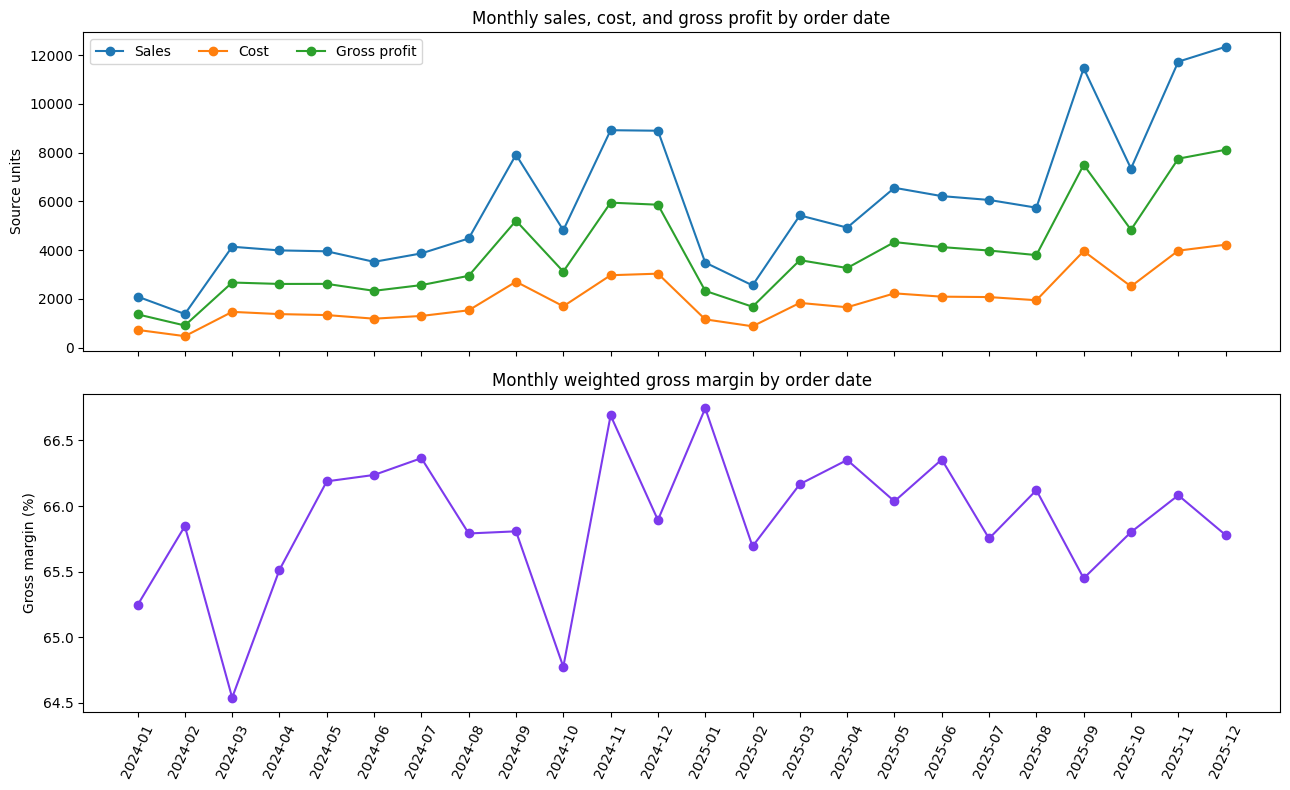

Order-date years present: 2024, 2025
Monthly margin range: 64.54%–66.75%; standard deviation 0.53 percentage points.


In [10]:
monthly = df.assign(Period=df["Order Date"].dt.to_period("M").astype("string"))
monthly = aggregate_by(monthly, "Period").sort_values("Period")
quarterly = df.assign(Period=df["Order Date"].dt.to_period("Q").astype("string"))
quarterly = aggregate_by(quarterly, "Period").sort_values("Period")
annual = df.assign(Period=df["Order Date"].dt.year.astype("string"))
annual = aggregate_by(annual, "Period").sort_values("Period")
print("Annual summary")
display(annual)
print("Monthly summary")
display(monthly[["Period", "Sales", "Cost", "Gross Profit", "Units", "Gross Margin %"]])
print("Quarterly summary")
display(quarterly[["Period", "Sales", "Cost", "Gross Profit", "Units", "Gross Margin %"]])

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
axes[0].plot(monthly["Period"], monthly["Sales"], marker="o", label="Sales")
axes[0].plot(monthly["Period"], monthly["Cost"], marker="o", label="Cost")
axes[0].plot(monthly["Period"], monthly["Gross Profit"], marker="o", label="Gross profit")
axes[0].set(title="Monthly sales, cost, and gross profit by order date", ylabel="Source units")
axes[0].legend(ncol=3)
axes[1].plot(monthly["Period"], monthly["Gross Margin %"], marker="o", color="#7c3aed")
axes[1].set(title="Monthly weighted gross margin by order date", ylabel="Gross margin (%)")
axes[1].tick_params(axis="x", rotation=65)
fig.tight_layout()
plt.show()

print(f"Order-date years present: {', '.join(annual['Period'].astype(str))}")
print(f"Monthly margin range: {monthly['Gross Margin %'].min():.2f}%–{monthly['Gross Margin %'].max():.2f}%; standard deviation {monthly['Gross Margin %'].std():.2f} percentage points.")

## 9. EDA takeaways and limitations

The statements below are generated directly from the dataset at notebook execution. They are descriptive; they do not establish why a margin, cost, or sales pattern occurs.

In [11]:
top_profit_product = products.iloc[0]
top_revenue_product = products.sort_values("Sales", ascending=False).iloc[0]
lowest_margin_product = products.sort_values("Gross Margin %").iloc[0]
lowest_margin_division = divisions.sort_values("Gross Margin %").iloc[0]
top_profit_division = divisions.sort_values("Gross Profit", ascending=False).iloc[0]
revenue_count, revenue_coverage = pareto_results["Sales"][1:]
profit_count, profit_coverage = pareto_results["Gross Profit"][1:]

print(f"Overall: sales {overall['Sales']:,.2f}; cost {overall['Cost']:,.2f}; gross profit {overall['Gross Profit']:,.2f}; weighted margin {overall['Gross Margin %']:.2f}%.")
print(f"Highest-profit product: {top_profit_product['Product Name']} ({top_profit_product['Gross Profit']:,.2f} gross profit; {top_profit_product['Profit Contribution %']:.2f}% profit share).")
print(f"Highest-revenue product: {top_revenue_product['Product Name']} ({top_revenue_product['Sales']:,.2f} sales).")
print(f"Lowest-margin product: {lowest_margin_product['Product Name']} ({lowest_margin_product['Gross Margin %']:.2f}%).")
print(f"Highest-profit division: {top_profit_division['Division']} ({top_profit_division['Profit Contribution %']:.2f}% profit contribution).")
print(f"Lowest-margin division: {lowest_margin_division['Division']} ({lowest_margin_division['Gross Margin %']:.2f}%).")
print(f"Pareto: {revenue_count} products reach {revenue_coverage:.2f}% revenue; {profit_count} products reach {profit_coverage:.2f}% gross profit.")
print(f"Factory financial results are unavailable: no product-to-factory mapping was supplied. The source does not specify currency.")

Overall: sales 141,783.63; cost 48,340.83; gross profit 93,442.80; weighted margin 65.91%.
Highest-profit product: Wonka Bar -Scrumdiddlyumptious (19,357.50 gross profit; 20.72% profit share).
Highest-revenue product: Wonka Bar - Triple Dazzle Caramel (28,485.00 sales).
Lowest-margin product: Kazookles (7.69%).
Highest-profit division: Chocolate (95.06% profit contribution).
Lowest-margin division: Other (44.84%).
Pareto: 5 products reach 92.88% revenue; 5 products reach 95.06% gross profit.
Factory financial results are unavailable: no product-to-factory mapping was supplied. The source does not specify currency.
